# Klasifikasi dengan Decision Tree & K-Nearest Neighbors (KNN)

## 1. Import Library & Pengaturan

In [1]:
# 202431048_Kania Pratiwi

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

DATA_DIR = ""

## 2. Fungsi Bantu

In [2]:
# 202431048_Kania Pratiwi

def buat_preprocessor(X, scaling):
    """Preprocessing: One-Hot untuk kategorikal, (opsional) StandardScaler untuk numerik."""
    kol_num = X.select_dtypes(include="number").columns.tolist()
    kol_kat = [c for c in X.columns if c not in kol_num]
    num_tf = StandardScaler() if scaling else "passthrough"
    return ColumnTransformer([
        ("num", num_tf, kol_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), kol_kat),
    ])


def evaluasi(nama_model, model, X_test, y_test, kelas):
    """Hitung metrik pada data test."""
    y_pred = model.predict(X_test)
    hasil = {
        "Model": nama_model,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall": recall_score(y_test, y_pred, average="macro"),
        "F1-macro": f1_score(y_test, y_pred, average="macro"),
    }
    print(f"--- {nama_model} ---")
    print(classification_report(y_test, y_pred, target_names=kelas, digits=3))
    return hasil, y_pred


def jalankan_eksperimen(nama_data, X, y_raw, cv_dt=5, cv_knn=3):
    """Latih & evaluasi Decision Tree + KNN pada satu dataset."""
    print("=" * 70)
    print(f"DATASET: {nama_data}   |   {X.shape[0]} baris, {X.shape[1]} fitur")
    print("=" * 70)

    # Encode target ke 0/1/...
    le = LabelEncoder()
    y = le.fit_transform(y_raw)
    kelas = [str(k) for k in le.classes_]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

    # ---------- Decision Tree ----------
    pipe_dt = Pipeline([
        ("prep", buat_preprocessor(X, scaling=False)),
        ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ])
    grid_dt = {
        "clf__criterion": ["gini", "entropy"],
        "clf__max_depth": [3, 5, 7, 10, None],
        "clf__min_samples_leaf": [1, 5, 10],
    }
    gs_dt = GridSearchCV(pipe_dt, grid_dt, cv=cv_dt, scoring="f1_macro", n_jobs=-1)
    gs_dt.fit(X_train, y_train)
    print("Parameter terbaik Decision Tree:", gs_dt.best_params_)

    # ---------- KNN ----------
    pipe_knn = Pipeline([
        ("prep", buat_preprocessor(X, scaling=True)),
        ("clf", KNeighborsClassifier()),
    ])
    grid_knn = {
        "clf__n_neighbors": [3, 5, 7, 11, 15],
        "clf__weights": ["uniform", "distance"],
    }
    gs_knn = GridSearchCV(pipe_knn, grid_knn, cv=cv_knn, scoring="f1_macro", n_jobs=-1)
    gs_knn.fit(X_train, y_train)
    print("Parameter terbaik KNN          :", gs_knn.best_params_, "\n")

    # ---------- Evaluasi ----------
    hasil_dt, pred_dt = evaluasi("Decision Tree", gs_dt.best_estimator_, X_test, y_test, kelas)
    hasil_knn, pred_knn = evaluasi("KNN", gs_knn.best_estimator_, X_test, y_test, kelas)

    # ---------- Visualisasi ----------
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    for a, (judul, pred) in zip(ax[:2], [("Decision Tree", pred_dt), ("KNN", pred_knn)]):
        ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=kelas).plot(
            ax=a, cmap="Blues", colorbar=False)
        a.set_title(f"Confusion Matrix - {judul}")
        a.grid(False)

    # Feature importance dari Decision Tree
    best_dt = gs_dt.best_estimator_
    nama_fitur = best_dt.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(best_dt.named_steps["clf"].feature_importances_, index=nama_fitur)
    imp.nlargest(10).sort_values().plot.barh(ax=ax[2], color="seagreen")
    ax[2].set_title("Top 10 Feature Importance (Decision Tree)")
    plt.suptitle(nama_data, fontsize=13, y=1.03)
    plt.tight_layout()
    plt.show()

    for h in (hasil_dt, hasil_knn):
        h["Dataset"] = nama_data
    return [hasil_dt, hasil_knn], gs_dt.best_estimator_, (X_train, X_test, y_train, y_test, kelas)


semua_hasil = []   

## 3. Dataset 1 - Heart Disease

In [3]:
# 202431048_Kania Pratiwi

df_heart = pd.read_csv(DATA_DIR + "01_heart_disease.csv")
print(df_heart.shape)
display(df_heart.head())
print("Missing value:", df_heart.isnull().sum().sum())
print(df_heart["HeartDisease"].value_counts())

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


Missing value: 0
HeartDisease
1    508
0    410
Name: count, dtype: int64


DATASET: Heart Disease   |   918 baris, 11 fitur
Parameter terbaik Decision Tree: {'clf__criterion': 'gini', 'clf__max_depth': 3, 'clf__min_samples_leaf': 10}
Parameter terbaik KNN          : {'clf__n_neighbors': 11, 'clf__weights': 'uniform'} 

--- Decision Tree ---
              precision    recall  f1-score   support

           0      0.769     0.854     0.809        82
           1      0.871     0.794     0.831       102

    accuracy                          0.821       184
   macro avg      0.820     0.824     0.820       184
weighted avg      0.826     0.821     0.821       184

--- KNN ---
              precision    recall  f1-score   support

           0      0.914     0.902     0.908        82
           1      0.922     0.931     0.927       102

    accuracy                          0.918       184
   macro avg      0.918     0.917     0.917       184
weighted avg      0.918     0.918     0.918       184



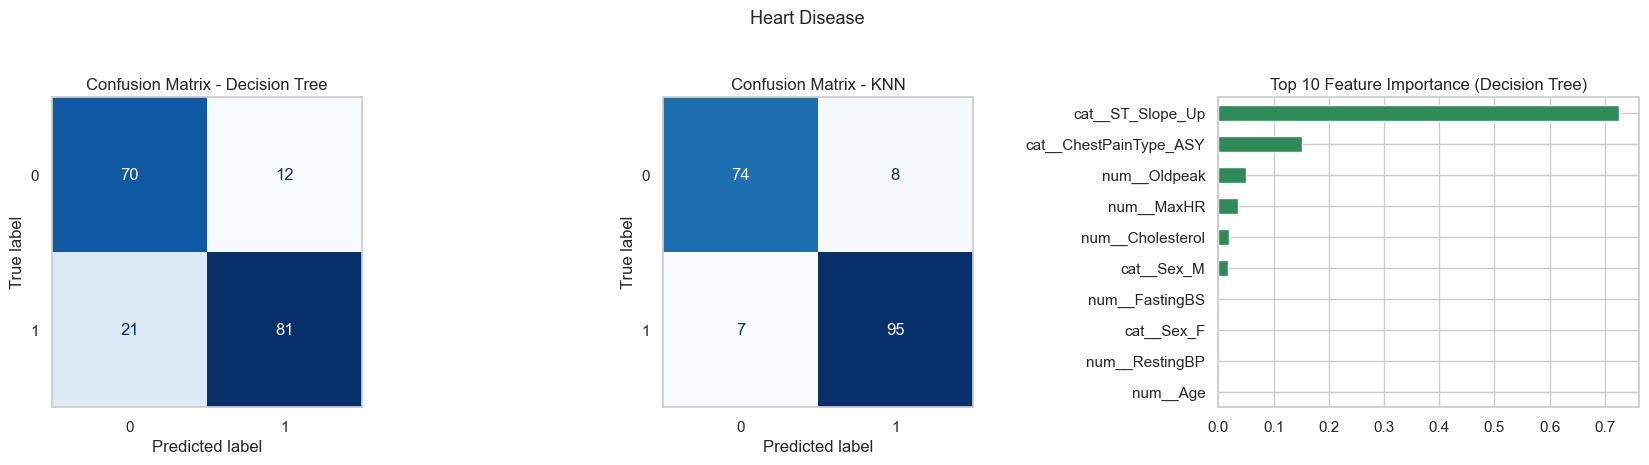

In [4]:
# 202431048_Kania Pratiwi

X = df_heart.drop(columns="HeartDisease")
y = df_heart["HeartDisease"]

hasil, dt_heart, split_heart = jalankan_eksperimen("Heart Disease", X, y)
semua_hasil += hasil

### Visualisasi pohon keputusan (Heart Disease)

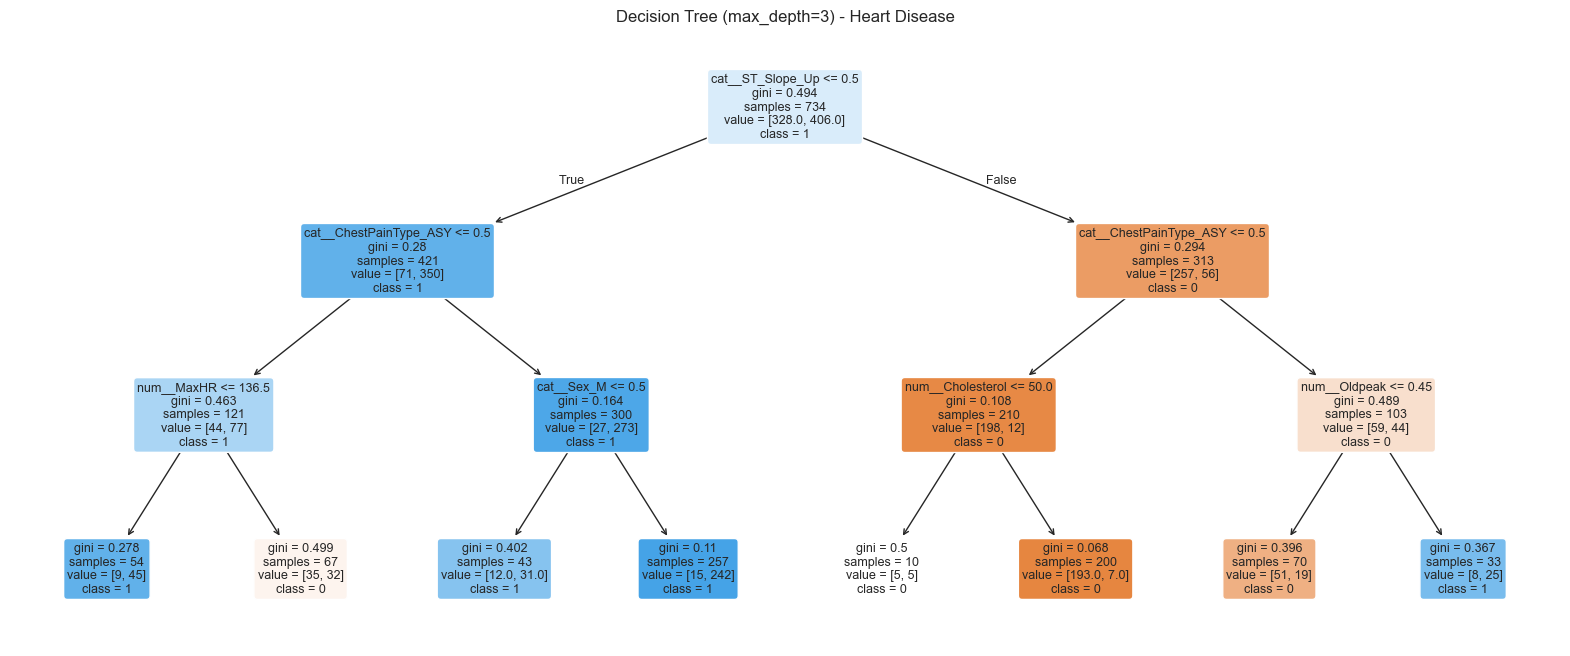

In [5]:
# 202431048_Kania Pratiwi

X_train, X_test, y_train, y_test, kelas = split_heart

dt_vis = Pipeline([
    ("prep", buat_preprocessor(X, scaling=False)),
    ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

plt.figure(figsize=(20, 8))
plot_tree(dt_vis.named_steps["clf"],
          feature_names=dt_vis.named_steps["prep"].get_feature_names_out(),
          class_names=kelas, filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3) - Heart Disease")
plt.show()

## 4. Dataset 2 - Diabetes

In [6]:
# 202431048_Kania Pratiwi

df_diab = pd.read_csv(DATA_DIR + "02_diabetes.csv")
print(df_diab.shape)
display(df_diab.head())
print("Missing value:", df_diab.isnull().sum().sum())
print(df_diab["diabetes"].value_counts())

(100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Missing value: 0
diabetes
0    91500
1     8500
Name: count, dtype: int64


DATASET: Diabetes   |   100000 baris, 8 fitur
Parameter terbaik Decision Tree: {'clf__criterion': 'gini', 'clf__max_depth': 10, 'clf__min_samples_leaf': 10}
Parameter terbaik KNN          : {'clf__n_neighbors': 7, 'clf__weights': 'uniform'} 

--- Decision Tree ---
              precision    recall  f1-score   support

           0      0.972     0.998     0.985     18300
           1      0.968     0.687     0.804      1700

    accuracy                          0.972     20000
   macro avg      0.970     0.842     0.894     20000
weighted avg      0.971     0.972     0.969     20000

--- KNN ---
              precision    recall  f1-score   support

           0      0.964     0.994     0.979     18300
           1      0.896     0.601     0.720      1700

    accuracy                          0.960     20000
   macro avg      0.930     0.797     0.849     20000
weighted avg      0.958     0.960     0.957     20000



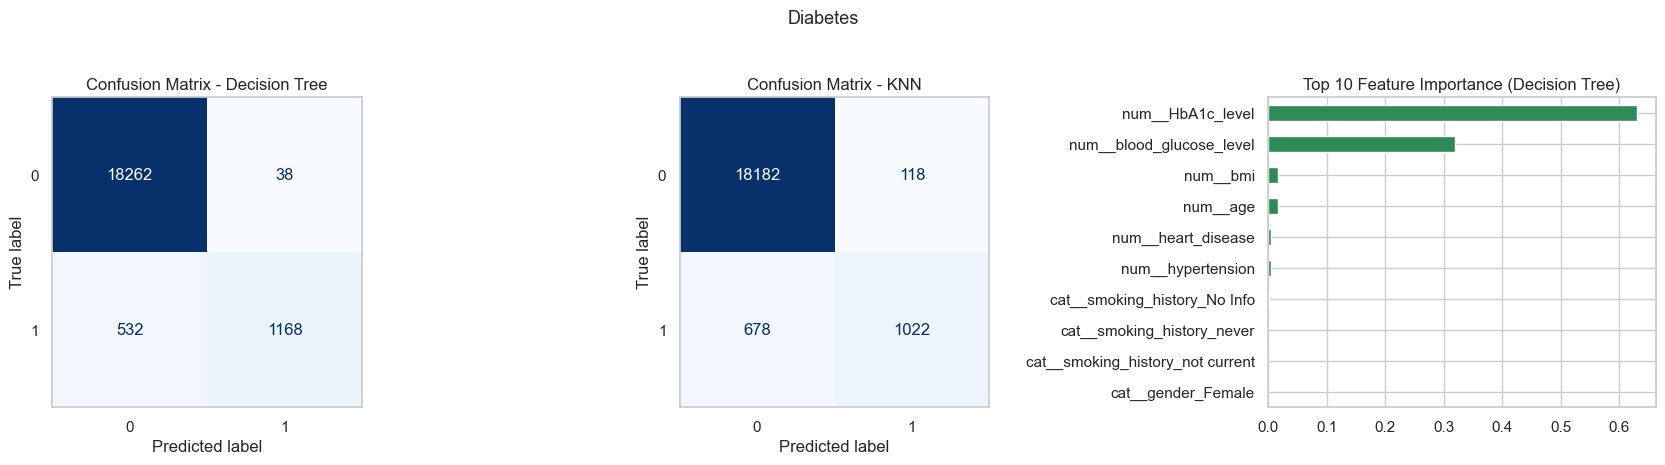

In [7]:
# 202431048_Kania Pratiwi

X = df_diab.drop(columns="diabetes")
y = df_diab["diabetes"]

hasil, dt_diab, split_diab = jalankan_eksperimen("Diabetes", X, y)
semua_hasil += hasil

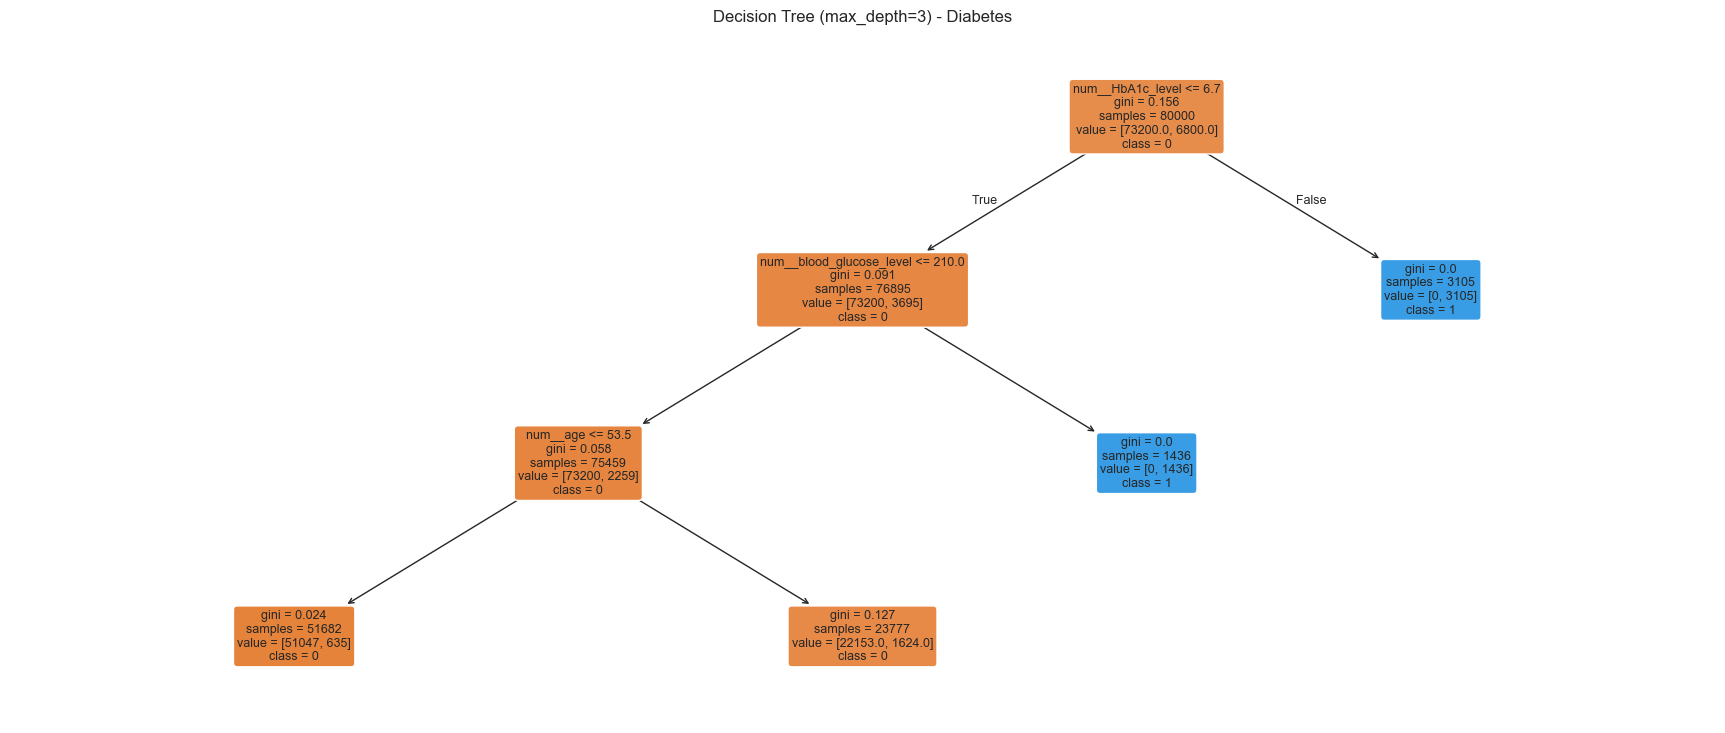

In [8]:
# 202431048_Kania Pratiwi

def gambar_pohon(nama, X, split, depth=3):
    X_train, X_test, y_train, y_test, kelas = split
    model = Pipeline([
        ("prep", buat_preprocessor(X, scaling=False)),
        ("clf", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)),
    ]).fit(X_train, y_train)

    plt.figure(figsize=(22, 9))
    plot_tree(model.named_steps["clf"],
              feature_names=model.named_steps["prep"].get_feature_names_out(),
              class_names=kelas, filled=True, rounded=True, fontsize=9)
    plt.title(f"Decision Tree (max_depth={depth}) - {nama}")
    plt.show()

gambar_pohon("Diabetes", df_diab.drop(columns="diabetes"), split_diab)

## 5. Dataset 3 - Counter-Strike 2

In [9]:
# 202431048_Kania Pratiwi

df_cs = pd.read_csv(DATA_DIR + "03_counter_strike_2.csv")
df_cs["bomb_planted"] = df_cs["bomb_planted"].astype(int)
print(df_cs.shape)
display(df_cs.head())
print("Missing value:", df_cs.isnull().sum().sum())
print(df_cs["round_winner"].value_counts())

(2000, 14)


,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,round_winner
0,175.00,0.0,0.0,de_dust2,0,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,CT
1,156.03,0.0,0.0,de_dust2,0,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,CT
2,96.03,0.0,0.0,de_dust2,0,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
3,76.03,0.0,0.0,de_dust2,0,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
4,174.97,1.0,0.0,de_dust2,0,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,CT


Missing value: 0
round_winner
T     1176
CT     824
Name: count, dtype: int64


DATASET: Counter-Strike 2   |   2000 baris, 13 fitur
Parameter terbaik Decision Tree: {'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__min_samples_leaf': 1}
Parameter terbaik KNN          : {'clf__n_neighbors': 5, 'clf__weights': 'distance'} 

--- Decision Tree ---
              precision    recall  f1-score   support

          CT      0.812     0.836     0.824       165
           T      0.883     0.864     0.873       235

    accuracy                          0.853       400
   macro avg      0.847     0.850     0.848       400
weighted avg      0.853     0.853     0.853       400

--- KNN ---
              precision    recall  f1-score   support

          CT      0.831     0.806     0.818       165
           T      0.867     0.885     0.876       235

    accuracy                          0.853       400
   macro avg      0.849     0.846     0.847       400
weighted avg      0.852     0.853     0.852       400



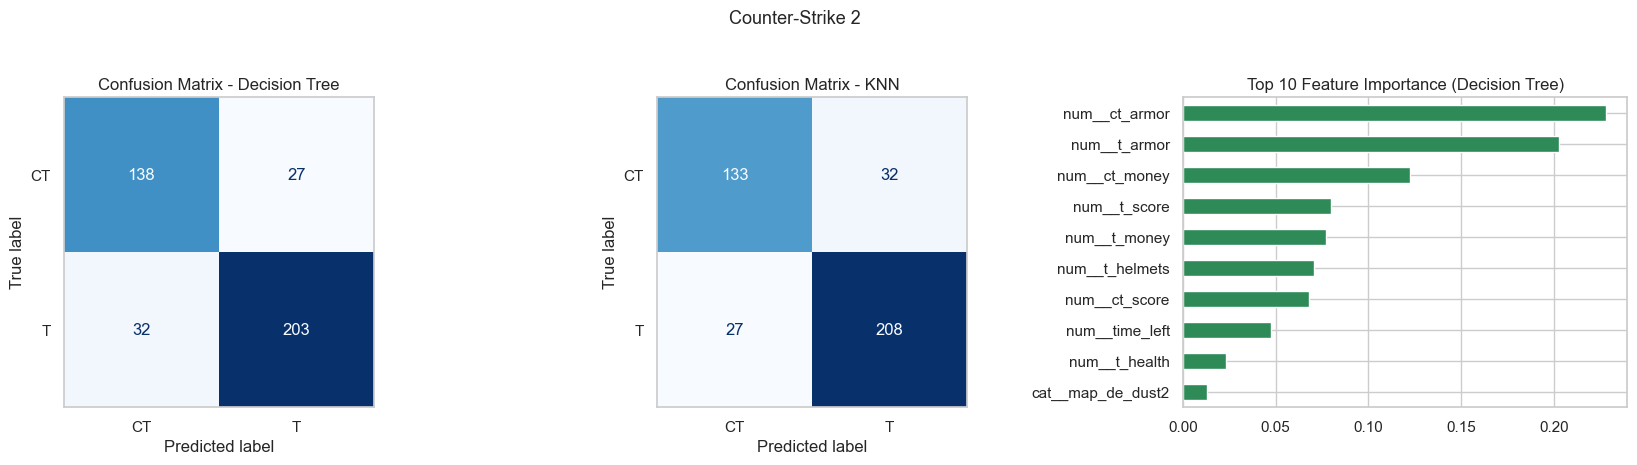

In [10]:
# 202431048_Kania Pratiwi

X = df_cs.drop(columns="round_winner")
y = df_cs["round_winner"]

hasil, dt_cs, split_cs = jalankan_eksperimen("Counter-Strike 2", X, y)
semua_hasil += hasil

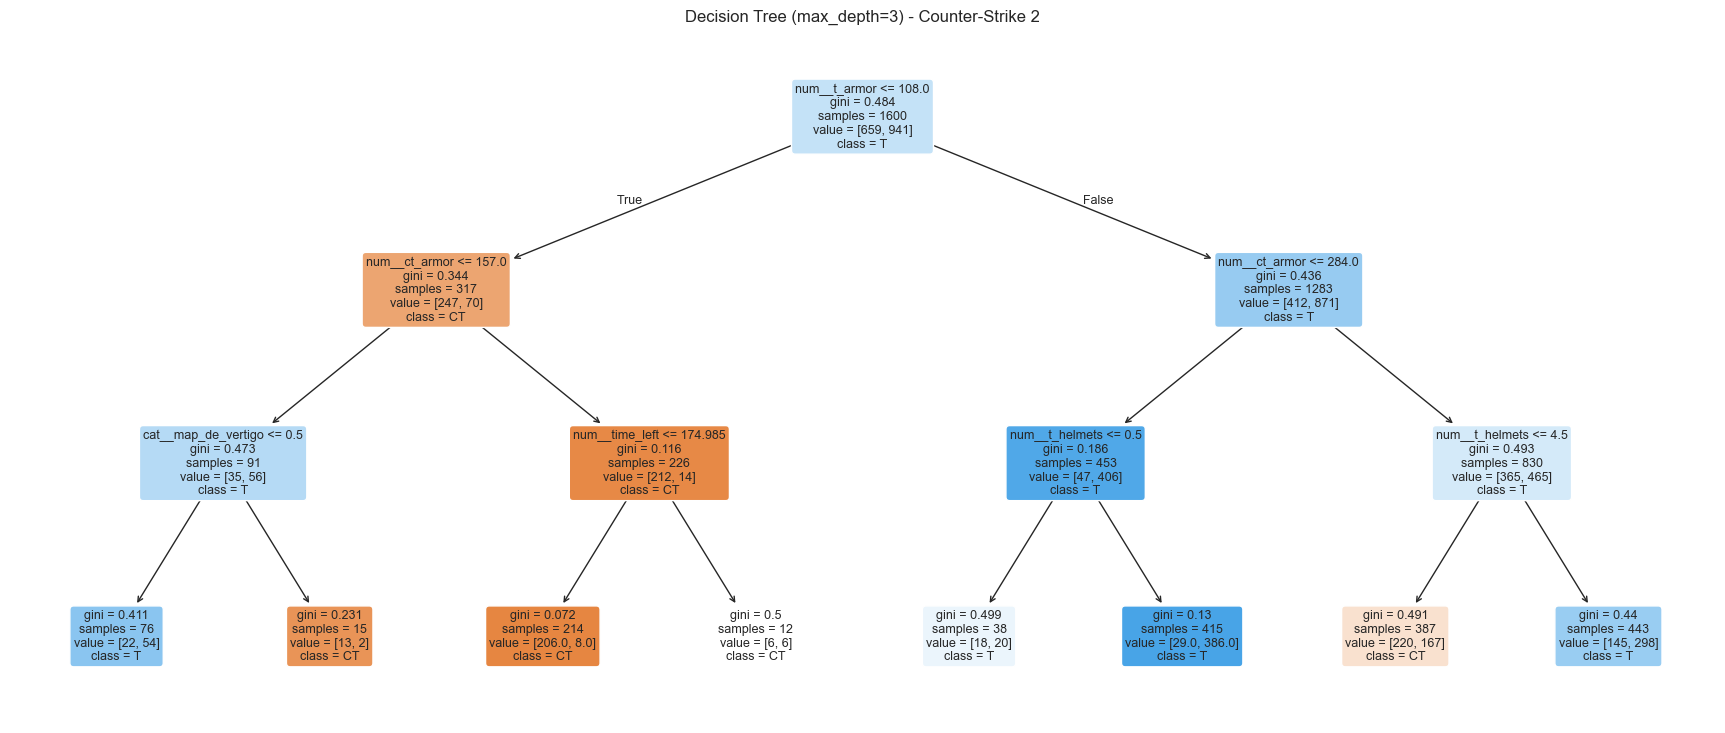

In [11]:
# 202431048_Kania Pratiwi

X_train, X_test, y_train, y_test, kelas = split_cs

model_pohon = Pipeline([
    ("prep", buat_preprocessor(df_cs.drop(columns="round_winner"), scaling=False)),
    ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

plt.figure(figsize=(22, 9))
plot_tree(model_pohon.named_steps["clf"],
          feature_names=model_pohon.named_steps["prep"].get_feature_names_out(),
          class_names=kelas, filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3) - Counter-Strike 2")
plt.show()

## 6. Dataset 4 - Bank Customers

In [12]:
# 202431048_Kania Pratiwi

df_bank = pd.read_csv(DATA_DIR + "04_bank_customers.csv", sep=";")
print(df_bank.shape)
display(df_bank.head())
print("Missing value:", df_bank.isnull().sum().sum())
print(df_bank["y"].value_counts())

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Missing value: 0
y
no     39922
yes     5289
Name: count, dtype: int64


DATASET: Bank Customers   |   45211 baris, 16 fitur
Parameter terbaik Decision Tree: {'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_samples_leaf': 10}
Parameter terbaik KNN          : {'clf__n_neighbors': 3, 'clf__weights': 'distance'} 

--- Decision Tree ---
              precision    recall  f1-score   support

          no      0.930     0.949     0.939      7985
         yes      0.543     0.462     0.499      1058

    accuracy                          0.892      9043
   macro avg      0.737     0.705     0.719      9043
weighted avg      0.885     0.892     0.888      9043

--- KNN ---
              precision    recall  f1-score   support

          no      0.920     0.964     0.941      7985
         yes      0.573     0.368     0.448      1058

    accuracy                          0.894      9043
   macro avg      0.746     0.666     0.695      9043
weighted avg      0.879     0.894     0.884      9043



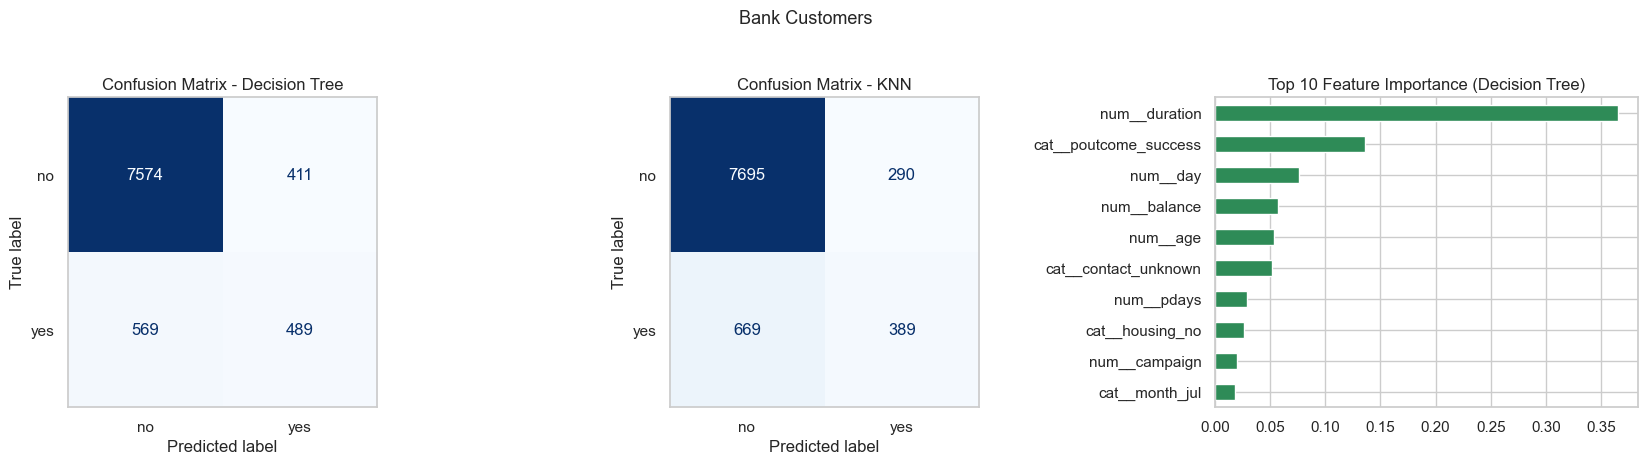

In [13]:
# 202431048_Kania Pratiwi

X = df_bank.drop(columns="y")
y = df_bank["y"]

hasil, dt_bank, split_bank = jalankan_eksperimen("Bank Customers", X, y)
semua_hasil += hasil

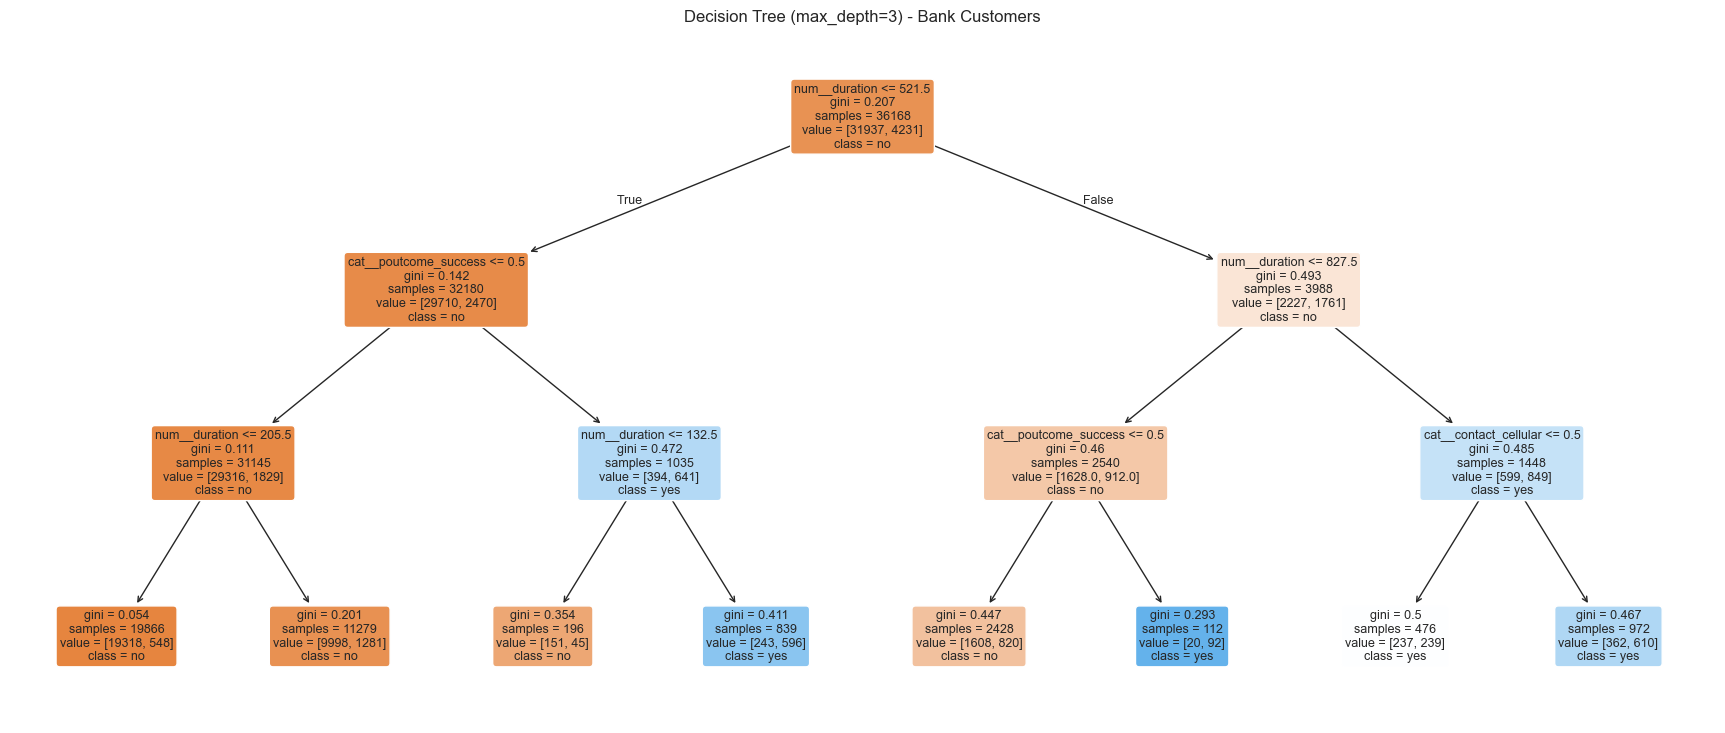

In [14]:
# 202431048_Kania Pratiwi

X_train, X_test, y_train, y_test, kelas = split_bank

model_pohon = Pipeline([
    ("prep", buat_preprocessor(df_bank.drop(columns="y"), scaling=False)),
    ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

plt.figure(figsize=(22, 9))
plot_tree(model_pohon.named_steps["clf"],
          feature_names=model_pohon.named_steps["prep"].get_feature_names_out(),
          class_names=kelas, filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3) - Bank Customers")
plt.show()

## 7. Perbandingan Hasil Semua Dataset

In [15]:
# 202431048_Kania Pratiwi

df_hasil = pd.DataFrame(semua_hasil)[["Dataset", "Model", "Accuracy", "Precision", "Recall", "F1-macro"]]
display(df_hasil.round(4))

,Dataset,Model,Accuracy,Precision,Recall,F1-macro
0,Heart Disease,Decision Tree,0.8207,0.8201,0.8239,0.8200
1,Heart Disease,KNN,0.9185,0.9180,0.9169,0.9174
2,Diabetes,Decision Tree,0.9715,0.9701,0.8425,0.8942
3,Diabetes,KNN,0.9602,0.9303,0.7974,0.8491
4,Counter-Strike 2,Decision Tree,0.8525,0.8472,0.8501,0.8485
5,Counter-Strike 2,KNN,0.8525,0.8490,0.8456,0.8471
6,Bank Customers,Decision Tree,0.8916,0.7367,0.7054,0.7194
7,Bank Customers,KNN,0.8940,0.7465,0.6657,0.6946


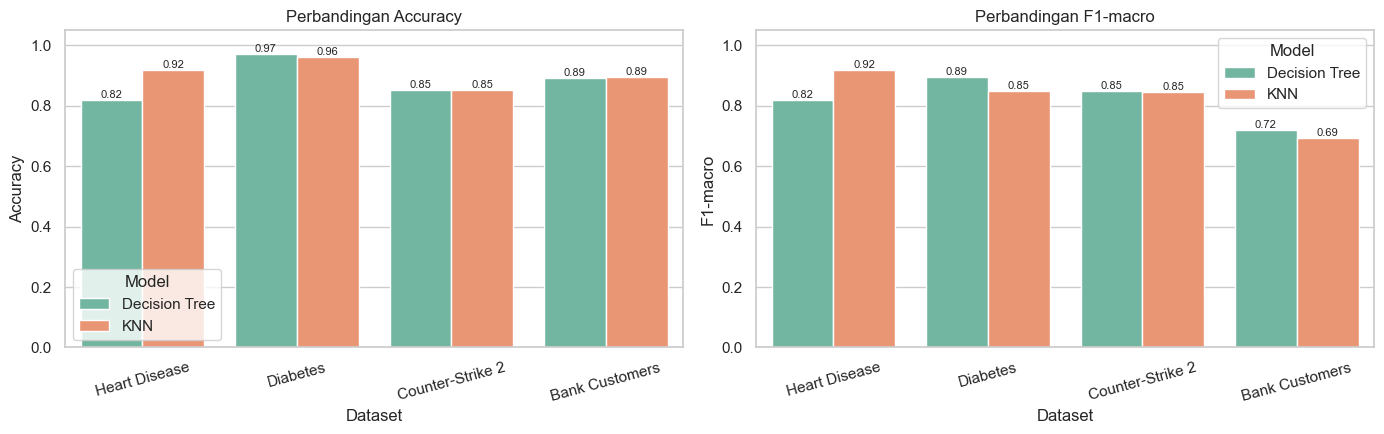

In [16]:
# 202431048_Kania Pratiwi

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, metrik in zip(ax, ["Accuracy", "F1-macro"]):
    sns.barplot(data=df_hasil, x="Dataset", y=metrik, hue="Model", ax=a, palette="Set2")
    a.set_title(f"Perbandingan {metrik}")
    a.set_ylim(0, 1.05)
    a.tick_params(axis="x", rotation=15)
    for c in a.containers:
        a.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()